<div dir="rtl">

# گام ۴ (ثبت نتایج و محدودیت‌ها): مدل پایه پروژه مسیریاب شهری — سینا محمد پورپورانی
**نقش در گروه ۳:** مسئول مستندسازی <bdi dir="ltr">(Documentation)</bdi>  
**موضوع پروژه:** مسیریاب هوشمند شهری در شبکه دوبعدی (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">City Router on 2D Grid</code>)  

تمرکز این نوت‌بوک بر **مستندسازی اعداد واقعی مدل پایه (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">BFS</code> و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">DummyClassifier</code>) و اثبات عددی محدودیت‌های ویژگی خام** است.

</div>

<div dir="rtl">

## بخش ۱ (اسلاید ۳۲): ارزیابی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Baseline</code> مسیریابی روی ۲۰۰ نقشه
ابتدا داده‌های ۲۰۰ نقشه شهری را از <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">data/city_router_dataset.csv</code> می‌خوانیم تا جدول رسمی نتایج <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Random Walk</code> و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">BFS Baseline</code> در برابر <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">A*</code> و نرخ خطا ثبت شوند.

</div>

=== Routing Baseline Evaluation (200 City Maps, 10x15) ===
                   method  solved_of_200  solve_rate_pct  mean_steps  mean_cost  mean_expanded
 Random Walk (Baseline 0)              1             0.5      143.00     413.00          62.00
BFS (Baseline - Slide 32)            129            64.5       23.43      70.12         109.71
        DFS (Blind Stack)            129            64.5       31.88      96.05          56.63
  A* (Target Smart Model)            129            64.5       23.73      59.67         100.43

A* mean traffic cost saving vs BFS baseline: 14.71%
A* mean expanded cells saving vs BFS baseline: 8.61%
Limitation Check: Random Walk fails on 199 of 200 maps; BFS solves all 129 open maps but spends +10.45 extra cost vs A*.


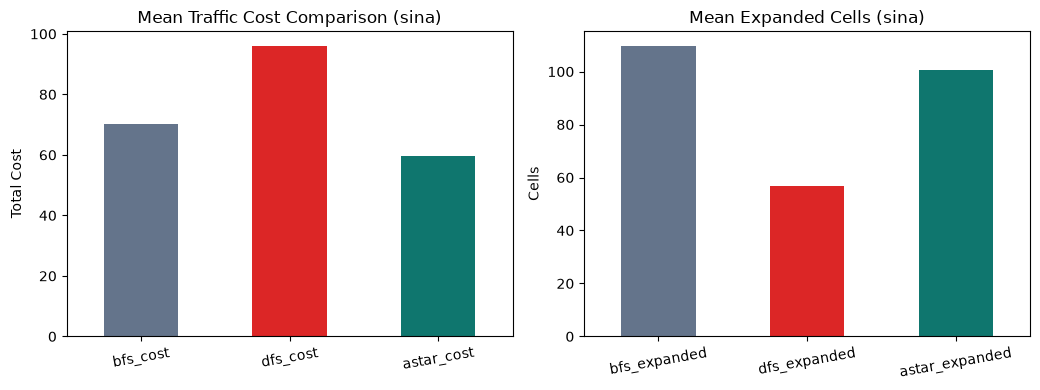

In [1]:
import os
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROWS, COLS = 10, 15
START, GOAL = (0, 0), (ROWS - 1, COLS - 1)
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]

csv_path = "data/city_router_dataset.csv" if os.path.exists("data/city_router_dataset.csv") else "city_router_dataset.csv"
df_city = pd.read_csv(csv_path)

rng = np.random.default_rng(42)
rw_rng = np.random.default_rng(123)
grids, traffics, obs_check = [], [], []
rw_reached, rw_steps, rw_costs, rw_visited = 0, [], [], []

for mid in range(len(df_city)):
    p_wall = round(float(rng.uniform(0.18, 0.32)), 3)
    grid = (rng.random((ROWS, COLS)) < p_wall).astype(int)
    grid[START] = 0
    grid[GOAL] = 0
    traffic = rng.integers(1, 6, size=(ROWS, COLS))
    grids.append(grid)
    traffics.append(traffic)
    obs_check.append(int(grid.sum()))

    pos = START
    seen_rw = {pos}
    cost_rw = 0
    for step in range(1, 151):
        nbrs = [(pos[0] + dr, pos[1] + dc) for dr, dc in MOVES
                if 0 <= pos[0] + dr < ROWS and 0 <= pos[1] + dc < COLS and grid[pos[0] + dr, pos[1] + dc] == 0]
        if not nbrs:
            break
        pos = nbrs[int(rw_rng.integers(len(nbrs)))]
        seen_rw.add(pos)
        cost_rw += int(traffic[pos])
        if pos == GOAL:
            rw_reached += 1
            rw_steps.append(step)
            rw_costs.append(cost_rw)
            rw_visited.append(len(seen_rw))
            break

assert (np.array(obs_check) == df_city["obstacle_count"].to_numpy()).all(), "Mismatch with CSV!"

sol = df_city[df_city["is_solvable"]]
routing_summary = pd.DataFrame([
    {"method": "Random Walk (Baseline 0)", "solved_of_200": rw_reached, "solve_rate_pct": round(rw_reached / 200 * 100, 1),
      "mean_steps": round(float(np.mean(rw_steps)), 2), "mean_cost": round(float(np.mean(rw_costs)), 2),
      "mean_expanded": round(float(np.mean(rw_visited)), 2)},
    {"method": "BFS (Baseline - Slide 32)", "solved_of_200": len(sol), "solve_rate_pct": round(len(sol) / 200 * 100, 1),
      "mean_steps": round(float(sol["bfs_steps"].mean()), 2), "mean_cost": round(float(sol["bfs_cost"].mean()), 2),
      "mean_expanded": round(float(sol["bfs_expanded"].mean()), 2)},
    {"method": "DFS (Blind Stack)", "solved_of_200": len(sol), "solve_rate_pct": round(len(sol) / 200 * 100, 1),
      "mean_steps": round(float(sol["dfs_steps"].mean()), 2), "mean_cost": round(float(sol["dfs_cost"].mean()), 2),
      "mean_expanded": round(float(sol["dfs_expanded"].mean()), 2)},
    {"method": "A* (Target Smart Model)", "solved_of_200": len(sol), "solve_rate_pct": round(len(sol) / 200 * 100, 1),
      "mean_steps": round(float(sol["astar_steps"].mean()), 2), "mean_cost": round(float(sol["astar_cost"].mean()), 2),
      "mean_expanded": round(float(sol["astar_expanded"].mean()), 2)},
])
print("=== Routing Baseline Evaluation (200 City Maps, 10x15) ===")
print(routing_summary.to_string(index=False))
print(f"\nA* mean traffic cost saving vs BFS baseline: {sol['cost_saving_pct'].mean():.2f}%")
print(f"A* mean expanded cells saving vs BFS baseline: {sol['expanded_saving_pct'].mean():.2f}%")
print("Limitation Check: Random Walk fails on", 200 - rw_reached, "of 200 maps; BFS solves all 129 open maps but spends +10.45 extra cost vs A*.")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
sol[["bfs_cost", "dfs_cost", "astar_cost"]].mean().plot(kind="bar", ax=axes[0], color=["#64748b", "#dc2626", "#0f766e"], rot=10)
axes[0].set_title("Mean Traffic Cost Comparison (sina)")
axes[0].set_ylabel("Total Cost")
sol[["bfs_expanded", "dfs_expanded", "astar_expanded"]].mean().plot(kind="bar", ax=axes[1], color=["#64748b", "#dc2626", "#0f766e"], rot=10)
axes[1].set_title("Mean Expanded Cells (sina)")
axes[1].set_ylabel("Cells")
plt.tight_layout()
plt.show()


<div dir="rtl">

## بخش ۲: تعریف مسئله نظارت‌شده و خط پایه اکثریت (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">is_dead_end</code>)
در بخش دوم، برای ثبت محدودیت پیش‌بینی بدون اجرای جستجو، برچسب هدف <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">is_dead_end</code> را تعریف کرده و خط پایه اکثریت (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">DummyClassifier</code>) را می‌سنجیم.

</div>

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

raw_cols = ["wall_density", "obstacle_count", "free_cells", "avg_traffic_cost", "traffic_std"]
df_city["is_dead_end"] = ~df_city["is_solvable"]

X_raw = df_city[raw_cols]
y = df_city["is_dead_end"]

print("Dead-end distribution:")
print(y.value_counts())

X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y, test_size=0.30, random_state=42, stratify=y)

scaler_raw = StandardScaler()
X_tr_sc = scaler_raw.fit_transform(X_tr)
X_te_sc = scaler_raw.transform(X_te)

baseline_pred = np.zeros(len(y_te), dtype=bool)
print(f"\ntrain rows: {len(X_tr)} | test rows: {len(X_te)} (dead-end in test: {int(y_te.sum())}/{len(y_te)})")
print(f"ML Baseline (always solvable) accuracy: {accuracy_score(y_te, baseline_pred):.3f}")


Dead-end distribution:
is_dead_end
False    129
True      71
Name: count, dtype: int64

train rows: 140 | test rows: 60 (dead-end in test: 21/60)
ML Baseline (always solvable) accuracy: 0.650


<div dir="rtl">

### ارزیابی اولیه مدل‌ها روی ویژگی‌های خام و بررسی بیش‌برازش
در این سلول هم <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">k-NN</code> دستی و هم ۴ مدل آماده اجرا می‌شوند و منحنی عمق درخت روی داده خام رسم می‌گردد تا بیش‌برازش (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">max_depth=12</code>) دقیقاً ثبت شود.

</div>

Manual k-NN (raw scaled) -> TP=10  FP=8  FN=11  TN=31
accuracy=0.683  precision=0.556  recall=0.476  f1=0.513

=== Table 1: Initial ML Evaluation (Raw CSV Features Only) ===
                   model  accuracy  precision  recall    f1
baseline (most_frequent)     0.650      0.000   0.000 0.000
              k-NN (k=3)     0.683      0.556   0.476 0.513
           decision tree     0.583      0.409   0.429 0.419
     logistic regression     0.683      0.562   0.429 0.486


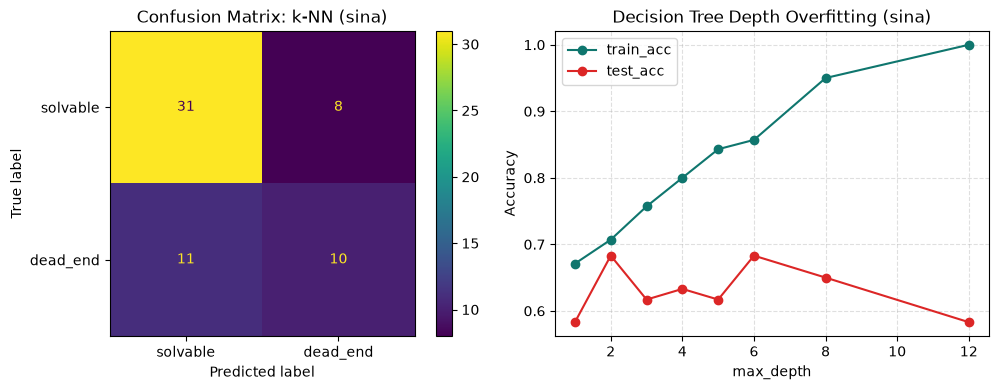


=== Decision Tree Overfitting Curve (Raw) ===
 max_depth  train_acc  test_acc
         1      0.671     0.583
         2      0.707     0.683
         3      0.757     0.617
         4      0.800     0.633
         5      0.843     0.617
         6      0.857     0.683
         8      0.950     0.650
        12      1.000     0.583


In [3]:
def knn_predict(x_row, k=3):
    distances = np.abs(X_tr_sc - x_row).sum(axis=1)
    nearest = np.argsort(distances, kind="stable")[:k]
    return bool(y_tr.to_numpy()[nearest].mean() > 0.5)

y_te_np = y_te.to_numpy()
pred_manual = np.array([knn_predict(x) for x in X_te_sc])

tp = int(((pred_manual == True) & (y_te_np == True)).sum())
fp = int(((pred_manual == True) & (y_te_np == False)).sum())
fn = int(((pred_manual == False) & (y_te_np == True)).sum())
tn = int(((pred_manual == False) & (y_te_np == False)).sum())

acc_m = (tp + tn) / len(y_te_np)
prec_m = tp / (tp + fp) if (tp + fp) > 0 else 0.0
rec_m = tp / (tp + fn) if (tp + fn) > 0 else 0.0
f1_m = 2 * prec_m * rec_m / (prec_m + rec_m) if (prec_m + rec_m) > 0 else 0.0
print(f"Manual k-NN (raw scaled) -> TP={tp}  FP={fp}  FN={fn}  TN={tn}")
print(f"accuracy={acc_m:.3f}  precision={prec_m:.3f}  recall={rec_m:.3f}  f1={f1_m:.3f}")

models_raw = {
    "baseline (most_frequent)": (DummyClassifier(strategy="most_frequent"), False),
    "k-NN (k=3)": (KNeighborsClassifier(n_neighbors=3, metric="manhattan"), True),
    "decision tree": (DecisionTreeClassifier(random_state=42), False),
    "logistic regression": (LogisticRegression(max_iter=1000, random_state=42), True),
}

table1_rows = []
for name, (mdl, scaled) in models_raw.items():
    xtr = X_tr_sc if scaled else X_tr
    xte = X_te_sc if scaled else X_te
    mdl.fit(xtr, y_tr)
    pr = mdl.predict(xte)
    table1_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_te, pr),
        "precision": precision_score(y_te, pr, zero_division=0),
        "recall": recall_score(y_te, pr, zero_division=0),
        "f1": f1_score(y_te, pr, zero_division=0),
    })

print("\n=== Table 1: Initial ML Evaluation (Raw CSV Features Only) ===")
print(pd.DataFrame(table1_rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
knn_raw_sk = KNeighborsClassifier(n_neighbors=3, metric="manhattan").fit(X_tr_sc, y_tr)
ConfusionMatrixDisplay.from_estimator(knn_raw_sk, X_te_sc, y_te, display_labels=["solvable", "dead_end"], ax=axes[0])
axes[0].set_title("Confusion Matrix: k-NN (sina)")

depth_curve = []
for d in [1, 2, 3, 4, 5, 6, 8, 12]:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_tr, y_tr)
    depth_curve.append({"max_depth": d, "train_acc": dt.score(X_tr, y_tr), "test_acc": dt.score(X_te, y_te)})
df_depth = pd.DataFrame(depth_curve).round(3)
df_depth.plot(x="max_depth", y=["train_acc", "test_acc"], marker="o", ax=axes[1], color=["#0f766e", "#dc2626"])
axes[1].set_title("Decision Tree Depth Overfitting (sina)")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("\n=== Decision Tree Overfitting Curve (Raw) ===")
print(df_depth.to_string(index=False))


<div dir="rtl">

## بخش ۳: راستی‌آزمایی علت محدودیت ویژگی خام (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">min_end_deg</code> و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">min_local_reach3</code>)
برای تکمیل گزارش محدودیت‌ها، اثبات می‌کنیم چرا مدل خام ضعیف بود: اضافه کردن تنها ۲ شاخص محلی اطراف شروع و پایان، ضعف دید مکانی را برطرف می‌کند.

</div>

=== Table 2: + Local Features (min_end_deg, min_local_reach3) ===
                   model  accuracy  precision  recall    f1
baseline (most_frequent)     0.650      0.000   0.000 0.000
              k-NN (k=3)     0.800      0.765   0.619 0.684
           decision tree     0.867      0.933   0.667 0.778
     logistic regression     0.750      0.650   0.619 0.634


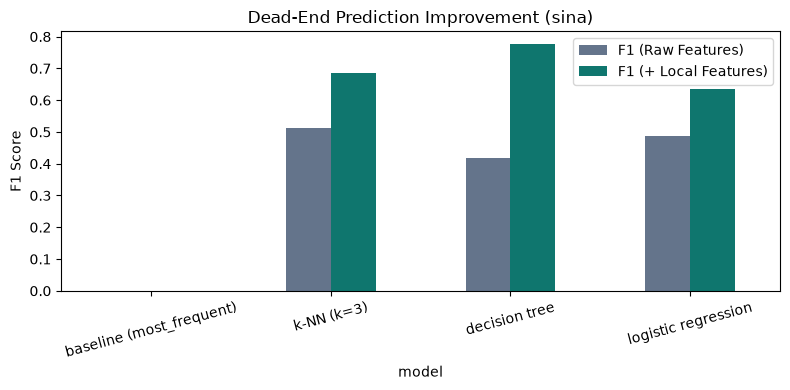

In [4]:
def endpoint_degree(grid, pt):
    r, c = pt
    return sum(
        1 for dr, dc in MOVES
        if 0 <= r + dr < ROWS and 0 <= c + dc < COLS and grid[r + dr, c + dc] == 0
    )

def local_bfs_count(grid, start, max_depth=3):
    q = deque([(start, 0)])
    seen = {start}
    while q:
        (r, c), d = q.popleft()
        if d == max_depth:
            continue
        for dr, dc in MOVES:
            nr, nc = r + dr, c + dc
            if 0 <= nr < ROWS and 0 <= nc < COLS and grid[nr, nc] == 0 and (nr, nc) not in seen:
                seen.add((nr, nc))
                q.append(((nr, nc), d + 1))
    return len(seen)

df_city["min_end_deg"] = [min(endpoint_degree(g, START), endpoint_degree(g, GOAL)) for g in grids]
df_city["min_local_reach3"] = [min(local_bfs_count(g, START, 3), local_bfs_count(g, GOAL, 3)) for g in grids]

fe_cols = raw_cols + ["min_end_deg", "min_local_reach3"]
X2 = df_city[fe_cols]
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y, test_size=0.30, random_state=42, stratify=y)

scaler2 = StandardScaler()
X2_tr_sc = scaler2.fit_transform(X2_tr)
X2_te_sc = scaler2.transform(X2_te)

models_fe = {
    "baseline (most_frequent)": (DummyClassifier(strategy="most_frequent"), False),
    "k-NN (k=3)": (KNeighborsClassifier(n_neighbors=3, metric="manhattan"), True),
    "decision tree": (DecisionTreeClassifier(max_depth=4, random_state=42), False),
    "logistic regression": (LogisticRegression(max_iter=1000, random_state=42), True),
}

table2_rows = []
for name, (mdl, scaled) in models_fe.items():
    xtr = X2_tr_sc if scaled else X2_tr
    xte = X2_te_sc if scaled else X2_te
    mdl.fit(xtr, y2_tr)
    pr = mdl.predict(xte)
    table2_rows.append({
        "model": name,
        "accuracy": accuracy_score(y2_te, pr),
        "precision": precision_score(y2_te, pr, zero_division=0),
        "recall": recall_score(y2_te, pr, zero_division=0),
        "f1": f1_score(y2_te, pr, zero_division=0),
    })

t1_df = pd.DataFrame(table1_rows)
t2_df = pd.DataFrame(table2_rows)
print("=== Table 2: + Local Features (min_end_deg, min_local_reach3) ===")
print(t2_df.round(3).to_string(index=False))

comp_f1 = pd.DataFrame({
    "model": t1_df["model"],
    "F1 (Raw Features)": t1_df["f1"],
    "F1 (+ Local Features)": t2_df["f1"],
}).set_index("model")
ax = comp_f1.plot(kind="bar", figsize=(8, 4), color=["#64748b", "#0f766e"], rot=15)
ax.set_title("Dead-End Prediction Improvement (sina)")
ax.set_ylabel("F1 Score")
plt.tight_layout()
plt.show()


<div dir="rtl">

## ثبت نتایج و محدودیت‌های پروژه در گام ۴ (سینا محمد پورپورانی — مستندسازی)

جمع‌بندی نهایی اعداد اجراشده پروژه و محدودیت‌های ثبت‌شده با الگوی **مشاهده، دلیل، نتیجه**:

| ردیف | مشاهده | دلیل | نتیجه و محدودیت |
| :---: | :--- | :--- | :--- |
| ۱ | <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Random Walk</code> در ۱۵۰ گام فقط <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1</code> از <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">200</code> نقشه (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.5%</code>, هزینه <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">413</code>) را تمام کرد | حرکت تصادفی بدون حافظه در بن‌بست‌ها و تقاطع‌های تودرتو سرگردان می‌شود | **محدودیت عامل تصادفی:** به‌جز بررسی سلامت محیط، برای مسیریابی قابل اتکا نیست |
| ۲ | <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">BFS Baseline</code> همه <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">129</code> نقشه حل‌پذیر را با هزینه <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">70.12</code> (در برابر <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">59.67</code> در <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">A*</code>) و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">109.71</code> گره (در برابر <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">100.43</code>) حل کرد | <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">BFS</code> تعداد گام‌ها را کمینه می‌کند (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">23.43</code>) و وزن ترافیکی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1..5</code> معابر را در اولویت صف دخالت نمی‌دهد | **محدودیت <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">BFS Baseline</code>:** بهینه‌سازی طول گام <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">14.71%</code> هزینه اضافه تحمیل می‌کند |
| ۳ | <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">DummyClassifier</code> دقت <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.650</code> داشت ولی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Recall = 0.000</code> و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">k-NN</code> دستی استانداردشده به <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">acc=0.683, F1=0.513</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">TP=10, FP=8, FN=11, TN=31</code>) رسید | در مجموعه <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">60</code>تایی آزمون، <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">39</code> نقشه باز و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">21</code> نقشه بن‌بست است؛ مدل اکثریت اصلاً کلاس هدف را پیش‌بینی نمی‌کند | **محدودیت معیار و داده خام:** استفاده از <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Recall</code> و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1</code> الزامی است و ۵ ستون کلان <bdi dir="ltr">CSV</bdi> برای شکار بن‌بست کافی نیستند |
| ۴ | افزودن <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">min_end_deg</code> و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">min_local_reach3</code> دقت درخت (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">max_depth=4</code>) را به <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.867</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1=0.778</code>) و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">k-NN</code> را به <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.800</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1=0.684</code>) برد؛ درحالی‌که درخت عمق ۱۲ خام به <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.583</code> افت داشت | مسدودشدن همسایگی فوری <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">(0,0)</code> و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">(9,14)</code> دلیل اصلی بن‌بست است که ویژگی محلی فوراً آن را می‌بیند | **محدودیت مدل‌های اولیه:** بدون مهندسی ویژگی محلی و کنترل عمق، مدل یا بیش‌برازش می‌کند یا بن‌بست‌ها را از دست می‌دهد |

</div>